# Alerta temprana de oferente único en la contratación pública colombiana
## Entregable III — Modelo final y artefactos para el despliegue

**Curso:** Inteligencia Artificial (535212), Universidad Autónoma de Occidente, 2026-2S
**Equipo:** Dilian Mayerly Madroñero Ortega · Juan Estevan Viera Cano

**Pregunta de investigación:** ¿es posible estimar, en el momento de la publicación de un proceso de contratación pública, la probabilidad de que reciba un solo oferente, usando únicamente la información disponible en ese instante?

---

> ### Alcance del sistema
>
> | El sistema estima | El sistema no estima |
> |---|---|
> | La **probabilidad de que un proceso reciba una sola oferta**, con la información disponible el día de su publicación | Si un proceso es **corrupto** |
> | Un **orden de prioridad** para la revisión humana | Si una entidad o un funcionario **incurrió en una falta** |
> | Las características del proceso **asociadas** con una menor competencia | Si existió **direccionamiento, fraude o ilegalidad** |
>
> El oferente único es un **indicador sustituto de riesgo** (Fazekas y Kocsis, 2020), no una prueba de irregularidad. La salida es una **lista priorizada para revisión humana**, bajo el principio de *priorizar, no señalar*.

### Qué agrega esta entrega frente al Entregable II

| Tema | Entregable II | Entregable III |
|---|---|---|
| Texto del objeto contractual | Aplazado | **E4**: TF-IDF + SVD · **E9**: embeddings de BETO (*transfer learning*) |
| Selección del modelo | E3 (LightGBM + historial) | E3 frente a E4 y E9, con prueba de McNemar |
| Métricas | Globales | Por clase, matriz de confusión, análisis del umbral (falsos positivos frente a falsos negativos) |
| Calibración | Diagnóstico: el modelo subestima en 2026 | Recalibración isotónica ajustada en 2025 |
| Producto | Lista en el notebook | **Artefactos exportados** que consume el *pipeline* semanal y la aplicación web |

### Contenido

| # | Sección |
|---|---|
| 1 | Configuración (Colab con GPU) |
| 2 | Datos, partición cronológica y métricas |
| 3 | Variables tabulares sin fuga de información |
| 4 | Representación del texto: E4 (TF-IDF) y E9 (BETO) |
| 5 | Experimentos y selección en validación (2025) |
| 6 | Evaluación final en prueba (2026) |
| 7 | Calibración de la probabilidad |
| 8 | Riesgo relativo a pares y equidad territorial |
| 9 | Explicabilidad (SHAP) |
| 10 | Exportación de artefactos para el despliegue |
| 11 | Conclusiones |

## 1. Configuración

**Metodología.** El notebook se ejecuta en Google Colab con GPU T4: la GPU solo se usa para extraer los embeddings de BETO (sección 4.3); el resto corre en CPU. Los datos se leen de Google Drive (`MyDrive/proyecto_IA/datos/`) y las salidas se escriben en `MyDrive/proyecto_IA/entregable3/`:

| Carpeta | Contenido |
|---|---|
| `figuras/` | Figuras numeradas para el documento y la presentación |
| `resultados/` | Tablas de métricas en CSV y resumen JSON |
| `artefactos/` | Modelo y tablas de referencia que consume el despliegue (sección 10) |
| `cache/` | Embeddings de BETO, para no recalcularlos en cada ejecución |

**Técnica.** BETO se usa con PyTorch (`transformers.AutoModel`) en media precisión (fp16), lo que permite procesar los ~400 000 textos en unos 5 minutos en la T4.

In [1]:
import importlib, json, subprocess, sys, time, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False


def asegurar(modulo, paquete_pip=None):
    # Importa un módulo y lo instala con pip solo si no está disponible
    try:
        return importlib.import_module(modulo)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete_pip or modulo], check=True)
        return importlib.import_module(modulo)


lgb = asegurar("lightgbm")
shap = asegurar("shap")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import transformers
from IPython.display import display
from scipy.stats import chi2
from sklearn.calibration import calibration_curve
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)

SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
COLOR_UNICO, COLOR_COMPETENCIA = "#c44e52", "#4c72b0"

VERSIONES = {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__,
             "lightgbm": lgb.__version__, "shap": shap.__version__, "torch": torch.__version__,
             "transformers": transformers.__version__}
print(f"Entorno: {'Google Colab' if EN_COLAB else 'local'} | dispositivo: {DISPOSITIVO}")
if DISPOSITIVO == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print(" | ".join(f"{k} {v}" for k, v in VERSIONES.items()))

Entorno: Google Colab | dispositivo: cuda
GPU: Tesla T4
pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | lightgbm 4.6.0 | shap 0.54.1 | torch 2.14.1+cu130 | transformers 5.22.1


In [2]:
ARCHIVO_DATOS = Path("datos") / "secop_procesos_limpio.parquet"

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_PROYECTO = Path("/content/drive/MyDrive/proyecto_IA")  # <- ajustar si la carpeta tiene otro nombre
else:
    RUTA_PROYECTO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / ARCHIVO_DATOS).exists()),
                         Path.cwd())

RUTA_DATOS = RUTA_PROYECTO / ARCHIVO_DATOS
if not RUTA_DATOS.exists():
    raise FileNotFoundError(f"No se encontró {RUTA_DATOS}. Suba 'secop_procesos_limpio.parquet' a "
                            "la carpeta 'datos/' del proyecto en Google Drive, o ajuste RUTA_PROYECTO.")

DIR_SALIDA = RUTA_PROYECTO / "entregable3"
DIR_FIG, DIR_RES = DIR_SALIDA / "figuras", DIR_SALIDA / "resultados"
DIR_ART, DIR_CACHE = DIR_SALIDA / "artefactos", DIR_SALIDA / "cache"
for d in (DIR_FIG, DIR_RES, DIR_ART, DIR_CACHE):
    d.mkdir(parents=True, exist_ok=True)


def guardar_figura(nombre):
    plt.savefig(DIR_FIG / f"{nombre}.png", dpi=150, bbox_inches="tight")


print(f"Datos: {RUTA_DATOS}\nSalidas: {DIR_SALIDA}")

Mounted at /content/drive
Datos: /content/drive/MyDrive/proyecto_IA/datos/secop_procesos_limpio.parquet
Salidas: /content/drive/MyDrive/proyecto_IA/entregable3


## 2. Datos, partición cronológica y métricas

**Metodología.** Se parte del conjunto limpio del Entregable I (procesos competitivos adjudicados de SECOP II, `p6dx-8zbt`) y se conservan las decisiones del Entregable II, que no se deshacen:

| Decisión | Justificación |
|---|---|
| Solo variables disponibles al publicar; se excluye `proveedores_invitados` | Se diligencia después de la publicación en menor cuantía y producía precisión@k = 1 de forma tautológica |
| Se excluyen los procesos sin fecha de publicación (0,84 %) | No se pueden ubicar en el tiempo |
| Partición cronológica: 2017–2024 entrenamiento, 2025 validación, 2026 prueba | La tasa de oferente único cambia con los años (deriva temporal); el modelo debe evaluarse en un año que no vio |
| Pesos por clase en la función de costo, sin remuestreo sintético | Por cada proceso con oferente único hay 1,88 con competencia en entrenamiento |
| Precisión@k como métrica de decisión y PR-AUC como métrica técnica | La usuaria revisa una cantidad limitada de procesos: importa que los primeros de la lista sean correctos |

El conjunto de prueba (2026) está protegido por un **candado**: sus etiquetas solo se leen en la sección 6, una única vez, después de elegir el modelo, el umbral y el calibrador en 2025.

In [3]:
COLUMNAS = [
    "id_del_proceso", "referencia_del_proceso", "entidad", "nit_entidad", "departamento_entidad",
    "ciudad_entidad", "ordenentidad", "modalidad_de_contratacion", "tipo_de_contrato",
    "codigo_principal_de_categoria", "segmento_unspsc", "numero_de_lotes", "precio_base",
    "log_precio_base", "duracion_dias", "dias_para_ofertar", "anio", "mes",
    "fecha_de_publicacion_del", "fecha_adjudicacion", "oferente_unico", "descripcion",
]
df = pd.read_parquet(RUTA_DATOS, columns=COLUMNAS)
# merge_asof exige el mismo tipo de fecha en ambas tablas
for c in ["fecha_de_publicacion_del", "fecha_adjudicacion"]:
    df[c] = pd.to_datetime(df[c]).astype("datetime64[ns]")

CATEGORICAS_TEXTO = ["entidad", "departamento_entidad", "ciudad_entidad", "ordenentidad",
                     "modalidad_de_contratacion", "tipo_de_contrato", "codigo_principal_de_categoria",
                     "segmento_unspsc"]
n_inicial = len(df)
df = df[df["fecha_de_publicacion_del"].notna()].copy()
df = df.sort_values("fecha_de_publicacion_del", kind="stable").reset_index(drop=True)
for c in CATEGORICAS_TEXTO:
    df[c] = df[c].fillna("Sin dato").astype(str)
df["descripcion"] = df["descripcion"].fillna("").astype(str)
df["anio"] = df["anio"].astype(int)
df["mes"] = df["mes"].astype(int)
df["oferente_unico"] = df["oferente_unico"].astype(int)
print(f"Procesos leídos: {n_inicial:,} | sin fecha de publicación: {n_inicial - len(df):,} | "
      f"disponibles: {len(df):,}")

# Partición cronológica
ANIO_MIN, ANIO_VAL, ANIO_PRUEBA = 2017, 2025, 2026
df["periodo"] = np.select(
    [df["anio"] < ANIO_MIN, df["anio"] < ANIO_VAL, df["anio"] == ANIO_VAL],
    ["excluido", "entrenamiento", "validación"], default="prueba")
m_tr = (df["periodo"] == "entrenamiento").to_numpy()
m_va = (df["periodo"] == "validación").to_numpy()
m_te = (df["periodo"] == "prueba").to_numpy()
y = df["oferente_unico"].to_numpy()
y_tr, y_va = y[m_tr], y[m_va]

_PRUEBA_ABIERTA = False


def datos_prueba():
    # Candado: las etiquetas de 2026 solo se leen en la sección 6
    if not _PRUEBA_ABIERTA:
        raise RuntimeError("El conjunto de prueba (2026) solo se usa en la sección 6.")
    return y[m_te]


resumen = (df.groupby("periodo")
             .agg(años=("anio", lambda s: f"{s.min()}–{s.max()}"), procesos=("anio", "size"),
                  tasa_oferente_unico=("oferente_unico", "mean"))
             .reindex(["excluido", "entrenamiento", "validación", "prueba"]))
resumen["tasa_oferente_unico"] = (resumen["tasa_oferente_unico"] * 100).round(1)
display(resumen)

N0, N1 = int((y_tr == 0).sum()), int((y_tr == 1).sum())
PESO_POS = N0 / N1
print(f"Peso de la clase positiva en la función de costo: w = N0/N1 = {PESO_POS:.3f}")

Procesos leídos: 404,324 | sin fecha de publicación: 3,395 | disponibles: 400,929


,años,procesos,tasa_oferente_unico
periodo,,,
excluido,2015–2016,857,32.7
entrenamiento,2017–2024,291053,34.7
validación,2025–2025,68430,43.1
prueba,2026–2026,40589,45.6


Peso de la clase positiva en la función de costo: w = N0/N1 = 1.883


In [4]:
def precision_en_k(y_real, puntaje, k):
    orden = np.argsort(-np.asarray(puntaje), kind="stable")[:k]
    return float(np.mean(np.asarray(y_real)[orden]))


def evaluar(y_real, puntaje):
    y_real, puntaje = np.asarray(y_real), np.asarray(puntaje)
    k1 = max(1, int(0.01 * len(y_real)))
    return {"PR-AUC": average_precision_score(y_real, puntaje),
            "ROC-AUC": roc_auc_score(y_real, puntaje),
            "P@100": precision_en_k(y_real, puntaje, 100),
            "P@500": precision_en_k(y_real, puntaje, 500),
            "P@1%": precision_en_k(y_real, puntaje, k1),
            "P@5%": precision_en_k(y_real, puntaje, max(1, int(0.05 * len(y_real)))),
            "prevalencia": float(y_real.mean())}


def mostrar(tabla, decimales=3):
    print(tabla.round(decimales).to_string())


RESULTADOS_VAL = {}


def registrar(nombre, puntaje_val):
    RESULTADOS_VAL[nombre] = evaluar(y_va, puntaje_val)
    mostrar(pd.DataFrame(RESULTADOS_VAL).T)


print(f"Validación 2025: prevalencia {y_va.mean():.1%} = PR-AUC de un puntaje al azar")

Validación 2025: prevalencia 43.1% = PR-AUC de un puntaje al azar


## 3. Variables tabulares sin fuga de información

**Concepto.** Una variable produce *fuga de información* cuando contiene algo que no se conoce en el momento de la predicción. Como el sistema se usa el día de la publicación, solo entran las características del proceso publicado y el historial de la entidad **conocido antes de esa fecha**.

**Metodología** (igual que en el Entregable II, sección 5):

| Grupo | Variables | Tratamiento |
|---|---|---|
| Categóricas de baja cardinalidad | modalidad, tipo de contrato, orden de la entidad, segmento UNSPSC, departamento | Categóricas nativas de LightGBM |
| Categóricas de alta cardinalidad | entidad, código UNSPSC, municipio | Frecuencia relativa calculada solo con entrenamiento |
| Numéricas | log del precio base, duración, días para ofertar, número de lotes, mes, año | Sin transformar (los árboles no requieren escalado) |
| Historial de la entidad | procesos previos y tasa suavizada de oferente único de la entidad y de la entidad en el segmento; días desde su última publicación | Solo procesos **adjudicados antes** de la fecha de publicación (`merge_asof` estrictamente anterior) |

La tasa suavizada es $\hat p = \dfrac{s + m\,p_0}{n + m}$, con $s$ procesos previos con oferente único de $n$ previos, $p_0$ la tasa global de entrenamiento y $m = 20$: una entidad con pocos procesos se acerca a $p_0$.

El tamaño del mercado municipal (`mercado_365`, publicaciones del municipio en los 365 días previos) y los quintiles de cuantía **no entran como predictores**: solo definen los pares de comparación (sección 8), para no dar al modelo una vía directa para castigar a los municipios pequeños.

In [5]:
CAT_BAJA = ["modalidad_de_contratacion", "tipo_de_contrato", "ordenentidad", "segmento_unspsc",
            "departamento_entidad"]
CAT_ALTA = ["entidad", "codigo_principal_de_categoria", "ciudad_entidad"]
NUMERICAS = ["log_precio_base", "duracion_dias", "dias_para_ofertar", "numero_de_lotes", "mes", "anio"]

# Frecuencias de alta cardinalidad (se exportan para el despliegue)
FRECUENCIAS = {}
for c in CAT_ALTA:
    FRECUENCIAS[c] = df.loc[m_tr, c].value_counts(normalize=True)
    df[f"frec_{c}"] = df[c].map(FRECUENCIAS[c]).fillna(0).astype("float32")
FRECUENCIA = [f"frec_{c}" for c in CAT_ALTA]

for c in NUMERICAS:
    df[c] = df[c].astype("float32")

# Copia en texto (claves de agrupación) y versión categórica (LightGBM)
CATEGORIAS = {}
for c in CAT_BAJA:
    df[f"{c}_txt"] = df[c]
    CATEGORIAS[c] = sorted(df.loc[m_tr, c].unique())
    df[c] = pd.Categorical(df[c], categories=CATEGORIAS[c])

VARS_TAB = CAT_BAJA + FRECUENCIA + NUMERICAS

# Historial de la entidad sin fuga
P0, M_SUAV = float(y_tr.mean()), 20


def clave_texto(datos, columnas):
    clave = datos[columnas[0]].astype(str)
    for c in columnas[1:]:
        clave = clave + "|" + datos[c].astype(str)
    return clave


def historial(columnas, prefijo):
    # Eventos: procesos cuyo resultado se conoce en la fecha de adjudicación
    ev = df.loc[df["fecha_adjudicacion"].notna(), ["fecha_adjudicacion", "oferente_unico"]].copy()
    ev["clave"] = clave_texto(df.loc[ev.index], columnas)
    ev = ev.sort_values("fecha_adjudicacion", kind="stable")
    ev["n_prev"] = ev.groupby("clave").cumcount() + 1
    ev["s_prev"] = ev.groupby("clave")["oferente_unico"].cumsum()
    consultas = pd.DataFrame({"fila": df.index, "clave": clave_texto(df, columnas),
                              "fecha": df["fecha_de_publicacion_del"]}).sort_values("fecha", kind="stable")
    unido = pd.merge_asof(consultas, ev[["clave", "fecha_adjudicacion", "n_prev", "s_prev"]],
                          left_on="fecha", right_on="fecha_adjudicacion", by="clave",
                          allow_exact_matches=False)  # estrictamente anterior
    unido = unido.set_index("fila").reindex(df.index)
    n, s = unido["n_prev"].fillna(0), unido["s_prev"].fillna(0)
    df[f"{prefijo}_n_prev"] = n.astype("float32")
    df[f"{prefijo}_tasa_prev"] = ((s + M_SUAV * P0) / (n + M_SUAV)).astype("float32")
    return ev  # se usa en la sección 10 para exportar el estado acumulado


inicio = time.time()
ev_ent = historial(["entidad"], "ent")
ev_entseg = historial(["entidad", "segmento_unspsc_txt"], "entseg")

pubs = (df[["entidad", "fecha_de_publicacion_del"]]
        .rename(columns={"fecha_de_publicacion_del": "fecha_anterior"})
        .sort_values("fecha_anterior", kind="stable"))
consultas = (pd.DataFrame({"fila": df.index, "entidad": df["entidad"], "fecha": df["fecha_de_publicacion_del"]})
             .sort_values("fecha", kind="stable"))
unido = pd.merge_asof(consultas, pubs, left_on="fecha", right_on="fecha_anterior", by="entidad",
                      allow_exact_matches=False).set_index("fila").reindex(df.index)
df["ent_dias_desde_ultimo"] = (unido["fecha"] - unido["fecha_anterior"]).dt.days.astype("float32")

HISTORIAL = ["ent_n_prev", "ent_tasa_prev", "entseg_n_prev", "entseg_tasa_prev", "ent_dias_desde_ultimo"]
VARS_E3 = VARS_TAB + HISTORIAL
print(f"Historial calculado en {time.time() - inicio:.1f} s | E3 usa {len(VARS_E3)} variables tabulares")
mostrar(df.loc[m_tr, HISTORIAL].describe().T, 2)

Historial calculado en 1.8 s | E3 usa 19 variables tabulares
                          count    mean     std   min    25%     50%     75%      max
ent_n_prev             291053.0  281.78  567.89  0.00  44.00  124.00  272.00  5174.00
ent_tasa_prev          291053.0    0.35    0.14  0.08   0.25    0.34    0.43     0.87
entseg_n_prev          291053.0   39.60  164.38  0.00   1.00    5.00   17.00  2050.00
entseg_tasa_prev       291053.0    0.35    0.10  0.02   0.31    0.35    0.38     0.91
ent_dias_desde_ultimo  288183.0   12.56   36.41  1.00   2.00    5.00   11.00  2047.00


## 4. Representación del texto del objeto contractual

El objeto del proceso (`descripcion`) es lenguaje natural redactado por la entidad y es público desde el primer día. La hipótesis es que el texto distingue necesidades que el código UNSPSC agrupa (por ejemplo, «mantenimiento de vehículos marca X» frente a «suministro de combustible»), y que los objetos muy específicos atraen menos oferentes. Se comparan dos representaciones:

| Experimento | Representación | Tipo de aprendizaje |
|---|---|---|
| **E4** | TF-IDF de palabras y bigramas, reducido con SVD truncada | Estadística de frecuencias, sin red neuronal |
| **E9** | Embeddings de **BETO** (BERT en español) congelado, reducidos con PCA | *Transfer learning*: representación aprendida por un Transformer preentrenado |

En ambos casos el vector de texto se **concatena** a las 19 variables de E3 y se entrena el mismo LightGBM, de modo que la diferencia de desempeño se atribuye solo al texto. Las transformaciones (vocabulario, IDF, SVD, PCA) se ajustan **solo con 2017–2024**.

### 4.1 E4: TF-IDF + SVD truncada

**Concepto.** TF-IDF pondera cada término $t$ de un documento $d$ por su frecuencia en el documento y por su rareza en el corpus:
$$\text{tfidf}(t,d) = \big(1 + \ln \text{tf}(t,d)\big)\cdot\Big(\ln\frac{1+N}{1+\text{df}(t)} + 1\Big)$$
(versión sublineal de scikit-learn), y cada fila se normaliza a norma L2. La matriz resultante es dispersa y de alta dimensión, por lo que se reduce con **SVD truncada** (análisis semántico latente), que proyecta los documentos sobre las $r$ direcciones de mayor varianza sin centrar la matriz.

**Técnica.** Palabras y bigramas, sin tildes, con frecuencia documental mínima de 5 y máximo 100 000 términos; $r = 100$ componentes.

In [6]:
textos = df["descripcion"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

inicio = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=100_000, sublinear_tf=True,
                        strip_accents="unicode", token_pattern=r"(?u)\b[^\W\d_]{2,}\b", dtype=np.float32)
tfidf.fit(textos[m_tr])
M_tfidf = tfidf.transform(textos)
svd = TruncatedSVD(n_components=100, random_state=SEMILLA)
svd.fit(M_tfidf[m_tr])
Z_tfidf = svd.transform(M_tfidf).astype("float32")
VARS_TFIDF = [f"tfidf_{i:03d}" for i in range(Z_tfidf.shape[1])]
df[VARS_TFIDF] = Z_tfidf
print(f"TF-IDF: vocabulario {len(tfidf.vocabulary_):,} términos | matriz {M_tfidf.shape} | "
      f"SVD {Z_tfidf.shape[1]} componentes, varianza explicada {svd.explained_variance_ratio_.sum():.1%} | "
      f"{time.time() - inicio:.0f} s")

# Términos con mayor peso en las tres primeras componentes (interpretación)
terminos = np.array(tfidf.get_feature_names_out())
for i in range(3):
    print(f"  componente {i}: {', '.join(terminos[np.argsort(-svd.components_[i])[:8]])}")

TF-IDF: vocabulario 100,000 términos | matriz (400929, 100000) | SVD 100 componentes, varianza explicada 15.7% | 67 s
  componente 0: de, la, del, el, para, de la, en, los
  componente 1: no definido, definido, no, combate no, combate, batallon, batallon de, de combate
  componente 2: preventivo, correctivo, mantenimiento preventivo, preventivo correctivo, mantenimiento, de mantenimiento, servicio, servicio de


### 4.2 E9: embeddings de BETO (*transfer learning*)

**Concepto.** BETO (Cañete et al., 2020) es un codificador BERT-base (12 bloques Transformer, $E = 768$, 12 cabezas de autoatención, ~110 M de parámetros) preentrenado en un corpus grande en español con modelado de lenguaje enmascarado. Cada bloque aplica autoatención multicabeza,
$$\text{Atención}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V,$$
seguida de una red *feed-forward*, con conexiones residuales y normalización de capa. La salida de la última capa (`last_hidden_state`) es un vector contextual de 768 componentes por subpalabra. Para representar todo el texto con un vector se comparan dos opciones:

| Agregación | Definición | Comentario |
|---|---|---|
| **[CLS]** | Vector del token especial inicial | Es la opción vista en clase (`Embedding_BERT_HuggingFace`); sin ajuste fino, el [CLS] de BERT no está entrenado para resumir la oración |
| **Media (*mean pooling*)** | Promedio de los vectores de las subpalabras reales (se excluye el relleno con la máscara de atención) | Recomendado por Reimers y Gurevych (2019) para embeddings de oraciones con BERT congelado |

**Metodología.** BETO se usa **congelado** (extracción de características): no se ajusta su peso, lo que evita entrenar 110 M de parámetros con 290 000 textos y mantiene barato el despliegue. En la tarea de clasificación de texto del curso, con el mismo corpus, el ajuste fino superó al [CLS] congelado + MLP, pero aquí el texto es solo una parte de la señal y el clasificador es LightGBM. Cada vector de 768 se reduce con PCA (ajustado en 2017–2024) a 64 componentes antes de concatenarlo.

**Técnica.** `dccuchile/bert-base-spanish-wwm-uncased`, textos en minúsculas, máximo 64 subpalabras (el 95 % de los objetos tiene 60 palabras o menos), lotes de 256 ordenados por longitud para reducir el relleno, media precisión (fp16) en la GPU. Los vectores reducidos se guardan en `cache/` para no recalcularlos.

In [7]:
from transformers import AutoModel, AutoTokenizer

MODELO_BETO = "dccuchile/bert-base-spanish-wwm-uncased"
MAX_LEN, LOTE_BETO, DIM_PCA = 64, 256, 64
CACHE_BETO = DIR_CACHE / f"beto_pca{DIM_PCA}.npz"


def embeddings_beto(lista_textos, tokenizador, modelo, dispositivo):
    # Devuelve los vectores [CLS] y la media de las subpalabras (768 c/u) de cada texto
    orden = np.argsort([len(t) for t in lista_textos])  # lotes de longitud similar
    cls = np.zeros((len(lista_textos), 768), dtype=np.float32)
    media = np.zeros((len(lista_textos), 768), dtype=np.float32)
    with torch.inference_mode():
        for i in range(0, len(orden), LOTE_BETO):
            idx = orden[i:i + LOTE_BETO]
            lote = tokenizador([lista_textos[j] for j in idx], truncation=True, max_length=MAX_LEN,
                               padding=True, return_tensors="pt").to(dispositivo)
            h = modelo(**lote).last_hidden_state                       # (lote, T, 768)
            mascara = lote["attention_mask"].unsqueeze(-1).to(h.dtype)  # 1 = subpalabra real
            cls[idx] = h[:, 0, :].float().cpu().numpy()
            media[idx] = ((h * mascara).sum(1) / mascara.sum(1)).float().cpu().numpy()
    return cls, media


if CACHE_BETO.exists():
    cache = np.load(CACHE_BETO)
    Z_cls, Z_media = cache["cls"], cache["media"]
    pca_cls, pca_media = joblib.load(DIR_CACHE / "pca_cls.joblib"), joblib.load(DIR_CACHE / "pca_media.joblib")
    print(f"Embeddings leídos de {CACHE_BETO}")
else:
    tok_beto = AutoTokenizer.from_pretrained(MODELO_BETO)
    beto = AutoModel.from_pretrained(MODELO_BETO).eval().to(DISPOSITIVO)
    if DISPOSITIVO == "cuda":
        beto = beto.half()
    n_param = sum(p.numel() for p in beto.parameters())
    inicio = time.time()
    E_cls, E_media = embeddings_beto(textos.tolist(), tok_beto, beto, DISPOSITIVO)
    print(f"BETO: {n_param / 1e6:.1f} M de parámetros congelados | {len(textos):,} textos en "
          f"{(time.time() - inicio) / 60:.1f} min")
    pca_cls = PCA(n_components=DIM_PCA, random_state=SEMILLA).fit(E_cls[m_tr])
    pca_media = PCA(n_components=DIM_PCA, random_state=SEMILLA).fit(E_media[m_tr])
    Z_cls = pca_cls.transform(E_cls).astype("float32")
    Z_media = pca_media.transform(E_media).astype("float32")
    np.savez(CACHE_BETO, cls=Z_cls, media=Z_media)
    joblib.dump(pca_cls, DIR_CACHE / "pca_cls.joblib")
    joblib.dump(pca_media, DIR_CACHE / "pca_media.joblib")
    del E_cls, E_media, beto
    torch.cuda.empty_cache()

VARS_CLS = [f"beto_cls_{i:02d}" for i in range(DIM_PCA)]
VARS_MEDIA = [f"beto_media_{i:02d}" for i in range(DIM_PCA)]
df[VARS_CLS], df[VARS_MEDIA] = Z_cls, Z_media
print(f"Varianza explicada por PCA-{DIM_PCA}: [CLS] {pca_cls.explained_variance_ratio_.sum():.1%} | "
      f"media {pca_media.explained_variance_ratio_.sum():.1%}")

config.json:   0%|          | 0.00/650 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/310 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/486k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

... (2 outputs left out)

[transformers] BertModel LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

BETO: 109.9 M de parámetros congelados | 400,929 textos en 3.9 min
Varianza explicada por PCA-64: [CLS] 71.2% | media 73.6%


## 5. Experimentos y selección en validación (2025)

**Metodología.** Todos los experimentos usan el mismo clasificador, LightGBM, con la configuración elegida por validación cruzada temporal en el Entregable II (`num_leaves = 31`, `min_child_samples = 50`, tasa de aprendizaje 0,05, submuestreo de filas y columnas de 0,8), peso de la clase positiva $w = 1{,}883$ (`scale_pos_weight`) y *early stopping* de 100 árboles sobre la PR-AUC de 2025. Solo cambia el conjunto de variables:

| Experimento | Variables |
|---|---|
| E3 (referencia del Entregable II) | 19 tabulares + historial |
| E4 | E3 + 100 componentes TF-IDF/SVD |
| E9-CLS | E3 + 64 componentes PCA del [CLS] de BETO |
| E9-media | E3 + 64 componentes PCA de la media de BETO |
| E4+E9 | E3 + TF-IDF/SVD + la mejor variante de BETO |

**Regla de selección (fijada antes de ver los resultados).** Se elige el experimento con mayor PR-AUC en 2025. Si la diferencia con un modelo más simple es menor que 0,005, se prefiere el más simple, porque cada representación de texto añade costo al despliegue (BETO exige cargar un modelo de 440 MB en el *pipeline* semanal).

**Concepto (LightGBM).** *Gradient boosting* construye árboles en secuencia; el árbol $m$ se ajusta al gradiente negativo de la pérdida (entropía cruzada binaria ponderada) respecto a la predicción acumulada $F_{m-1}$, y $F_m = F_{m-1} + \eta\, f_m$. LightGBM crece los árboles por hoja (*leaf-wise*) y agrupa los valores continuos en histogramas, lo que lo hace rápido en CPU con cientos de miles de filas.

In [8]:
PARAMS_LGBM = dict(objective="binary", metric="average_precision", n_estimators=3000, learning_rate=0.05,
                   num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
                   colsample_bytree=0.8, reg_lambda=1.0, scale_pos_weight=PESO_POS,
                   random_state=SEMILLA, n_jobs=-1, verbose=-1)
MODELOS, PUNTAJES, TIEMPOS, VARIABLES = {}, {}, {}, {}


def experimento(nombre, variables):
    inicio = time.time()
    modelo = lgb.LGBMClassifier(**PARAMS_LGBM)
    modelo.fit(df.loc[m_tr, variables], y_tr, eval_set=[(df.loc[m_va, variables], y_va)],
               callbacks=[lgb.early_stopping(100, verbose=False)])
    MODELOS[nombre], VARIABLES[nombre] = modelo, variables
    PUNTAJES[nombre] = modelo.predict_proba(df[variables])[:, 1]  # puntaje ponderado (sin corregir)
    TIEMPOS[nombre] = time.time() - inicio
    print(f"{nombre}: {len(variables)} variables, {modelo.best_iteration_} árboles, {TIEMPOS[nombre]:.0f} s")
    registrar(nombre, PUNTAJES[nombre][m_va])


experimento("E3", VARS_E3)
experimento("E4", VARS_E3 + VARS_TFIDF)
experimento("E9-CLS", VARS_E3 + VARS_CLS)
experimento("E9-media", VARS_E3 + VARS_MEDIA)

E3: 19 variables, 1044 árboles, 25 s
    PR-AUC  ROC-AUC  P@100  P@500   P@1%   P@5%  prevalencia
E3   0.786    0.834   0.98  0.972  0.975  0.918        0.431
E4: 119 variables, 1144 árboles, 59 s
    PR-AUC  ROC-AUC  P@100  P@500   P@1%   P@5%  prevalencia
E3   0.786    0.834   0.98  0.972  0.975  0.918        0.431
E4   0.794    0.842   0.99  0.956  0.959  0.928        0.431
E9-CLS: 83 variables, 1060 árboles, 47 s
        PR-AUC  ROC-AUC  P@100  P@500   P@1%   P@5%  prevalencia
E3       0.786    0.834   0.98  0.972  0.975  0.918        0.431
E4       0.794    0.842   0.99  0.956  0.959  0.928        0.431
E9-CLS   0.786    0.835   0.95  0.952  0.953  0.932        0.431
E9-media: 83 variables, 1824 árboles, 86 s
          PR-AUC  ROC-AUC  P@100  P@500   P@1%   P@5%  prevalencia
E3         0.786    0.834   0.98  0.972  0.975  0.918        0.431
E4         0.794    0.842   0.99  0.956  0.959  0.928        0.431
E9-CLS     0.786    0.835   0.95  0.952  0.953  0.932        0.431
E9-media

E4+E9: 183 variables, 1440 árboles, 100 s
          PR-AUC  ROC-AUC  P@100  P@500   P@1%   P@5%  prevalencia
E3         0.786    0.834   0.98  0.972  0.975  0.918        0.431
E4         0.794    0.842   0.99  0.956  0.959  0.928        0.431
E9-CLS     0.786    0.835   0.95  0.952  0.953  0.932        0.431
E9-media   0.793    0.840   0.96  0.960  0.958  0.926        0.431
E4+E9      0.794    0.842   0.97  0.964  0.953  0.931        0.431

Mejor variante de BETO: E9-media | modelo elegido en validación: E4


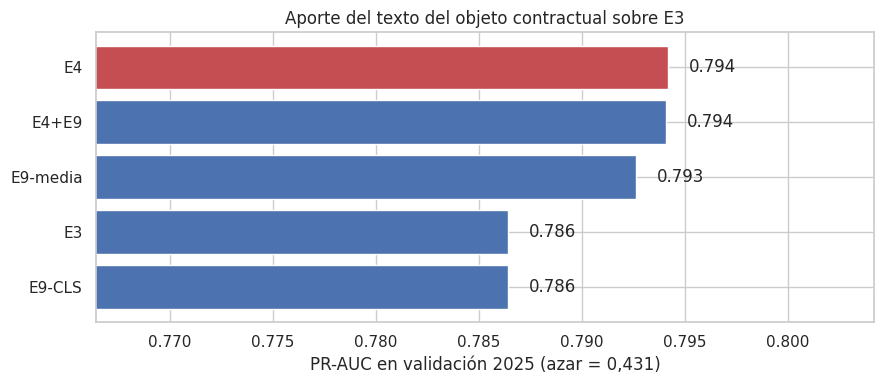

In [9]:
MEJOR_BETO = max(["E9-CLS", "E9-media"], key=lambda k: RESULTADOS_VAL[k]["PR-AUC"])
VARS_BETO = VARS_CLS if MEJOR_BETO == "E9-CLS" else VARS_MEDIA
experimento("E4+E9", VARS_E3 + VARS_TFIDF + VARS_BETO)

tabla_val = pd.DataFrame(RESULTADOS_VAL).T
tabla_val["variables"] = [len(VARIABLES[k]) for k in tabla_val.index]
tabla_val["árboles"] = [MODELOS[k].best_iteration_ for k in tabla_val.index]
tabla_val["tiempo_s"] = [round(TIEMPOS[k]) for k in tabla_val.index]
tabla_val.to_csv(DIR_RES / "metricas_validacion_2025.csv")

# Regla de selección: mayor PR-AUC; ante diferencias < 0,005 se prefiere el más simple
COMPLEJIDAD = ["E3", "E4", MEJOR_BETO, "E4+E9"]   # de más simple a más costoso de desplegar
mejor_prauc = tabla_val.loc[COMPLEJIDAD, "PR-AUC"].max()
ELEGIDO = next(k for k in COMPLEJIDAD if tabla_val.loc[k, "PR-AUC"] >= mejor_prauc - 0.005)
print(f"\nMejor variante de BETO: {MEJOR_BETO} | modelo elegido en validación: {ELEGIDO}")

fig, ax = plt.subplots(figsize=(9, 4))
orden = tabla_val.sort_values("PR-AUC").index
colores = [COLOR_UNICO if k == ELEGIDO else COLOR_COMPETENCIA for k in orden]
ax.barh(orden, tabla_val.loc[orden, "PR-AUC"], color=colores)
for i, k in enumerate(orden):
    ax.text(tabla_val.loc[k, "PR-AUC"] + 0.001, i, f"{tabla_val.loc[k, 'PR-AUC']:.3f}", va="center")
ax.set_xlim(tabla_val["PR-AUC"].min() - 0.02, tabla_val["PR-AUC"].max() + 0.01)
ax.set_xlabel("PR-AUC en validación 2025 (azar = 0,431)")
ax.set_title("Aporte del texto del objeto contractual sobre E3")
plt.tight_layout()
guardar_figura("01_seleccion_validacion")
plt.show()

### 5.1 Lectura de la selección

- **El texto aporta señal, pero moderada.** E4 y E9-media suben la PR-AUC de 2025 de 0,786 a 0,793–0,794 y mejoran la precisión en el 5 % superior de la lista; la mayor parte de la señal sigue estando en el historial de la entidad y en la modalidad.
- **TF-IDF iguala a BETO.** La media de BETO (0,793) rinde igual que TF-IDF (0,794), y combinarlos (E4+E9) no suma. Es coherente con la tarea de clasificación de texto del curso sobre el mismo corpus: los objetos contractuales usan un vocabulario cerrado y formulaico, que una representación de frecuencias ya captura. El *transfer learning* aporta cuando el significado depende del contexto, lo que aquí ocurre poco.
- **[CLS] frente a media.** Con BETO congelado, la media de las subpalabras supera al [CLS] (0,793 frente a 0,786), como anticipa la literatura: sin ajuste fino, el [CLS] no está entrenado para resumir la oración.
- **Decisión.** Por la regla fijada antes de ver los resultados, se elige **E4**: tiene la PR-AUC más alta y es el más simple de desplegar (un vectorizador y una SVD de scikit-learn, sin GPU ni un modelo de 440 MB en el *pipeline*).
- **Costo en el tope de la lista.** En 2025 el texto reduce la precisión en el 1 % superior (0,975 → 0,959, unos 11 procesos de 684). Se verifica en prueba (sección 6) si la caída se mantiene.

### 5.2 Umbral y calibración (ajustados en 2025)

**Concepto.** El modelo entrega un puntaje; convertirlo en una decisión exige un **umbral**. Un falso positivo es una alerta sobre un proceso que sí tuvo competencia; un falso negativo, un proceso con oferente único que no se alertó. En este problema **el error más costoso es el falso positivo**: la usuaria tiene capacidad limitada de revisión (en 2026 hubo más de 18 000 procesos con oferente único) y cada falsa alarma consume tiempo y apunta sin razón a una entidad. Un falso negativo es un proceso que no se revisa, lo que de todos modos ocurre con la mayoría por falta de capacidad. Por eso se reportan dos puntos de operación:

| Punto de operación | Criterio en 2025 | Uso |
|---|---|---|
| **Equilibrado** | Umbral que maximiza F1 | Comparación con el Entregable II |
| **Alta precisión** | Menor umbral con precisión ≥ 0,80 | Alerta del producto: privilegia evitar falsos positivos |

**Calibración.** Los pesos por clase desplazan las probabilidades; se corrigen con $\text{logit}(p) - \ln w$. Además, el modelo se entrenó con años en que la tasa de oferente único era menor (34,7 %) y en 2025–2026 subestima el riesgo (Entregable II, sección 8). Se ajusta una **regresión isotónica** sobre la probabilidad corregida de 2025: una función monótona no decreciente por tramos que lleva cada puntaje a la frecuencia observada, de modo que «70 %» signifique 70 %. Como agrupa puntajes en tramos planos, introduce empates; por eso **el orden de la lista usa el puntaje sin calibrar** y la probabilidad calibrada solo se muestra al usuario.

In [10]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def prob_corregida(p, peso=PESO_POS):
    return 1 / (1 + np.exp(-(logit(p) - np.log(peso))))


modelo_final, VARS_FINAL = MODELOS[ELEGIDO], VARIABLES[ELEGIDO]
puntaje = PUNTAJES[ELEGIDO]            # puntaje ponderado
prob_sin_cal = prob_corregida(puntaje)  # corrección por pesos

# Umbrales en validación (sobre la probabilidad corregida)
prec, rec, umbrales = precision_recall_curve(y_va, prob_sin_cal[m_va])
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
i_f1 = int(np.argmax(f1[:-1]))
i_ap = int(np.argmax(prec[:-1] >= 0.80))
UMBRALES = {"equilibrado (máx. F1)": float(umbrales[i_f1]), "alta precisión (P ≥ 0,80)": float(umbrales[i_ap])}
for nombre, i in [("equilibrado (máx. F1)", i_f1), ("alta precisión (P ≥ 0,80)", i_ap)]:
    print(f"{nombre}: umbral {umbrales[i]:.3f} | validación: precisión {prec[i]:.3f}, "
          f"recall {rec[i]:.3f}, F1 {f1[i]:.3f}, alertas {int((prob_sin_cal[m_va] >= umbrales[i]).sum()):,}")

# Calibración isotónica ajustada en 2025
calibrador = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
calibrador.fit(prob_sin_cal[m_va], y_va)
prob_cal = calibrador.predict(prob_sin_cal)
print(f"\nProbabilidad media en 2025: sin calibrar {prob_sin_cal[m_va].mean():.3f} | calibrada "
      f"{prob_cal[m_va].mean():.3f} | tasa real {y_va.mean():.3f}")

equilibrado (máx. F1): umbral 0.306 | validación: precisión 0.671, recall 0.827, F1 0.741, alertas 36,358
alta precisión (P ≥ 0,80): umbral 0.571 | validación: precisión 0.800, recall 0.562, F1 0.660, alertas 20,715

Probabilidad media en 2025: sin calibrar 0.393 | calibrada 0.431 | tasa real 0.431


## 6. Evaluación final en prueba (2026)

**Metodología.** Con el modelo, los umbrales y el calibrador fijados en 2025, se abre el candado y se evalúa **una sola vez** en 2026 (40 589 procesos que no intervinieron en ninguna decisión). Se reporta:

1. Métricas de ranking de todos los experimentos (PR-AUC, ROC-AUC, precisión@k).
2. Para el modelo elegido, métricas **por clase** y matriz de confusión en los dos puntos de operación.
3. Comparación estadística con E3:
   - **Prueba de McNemar** sobre las decisiones binarias (umbral de máximo F1 de cada modelo). Solo cuentan los procesos en que los modelos discrepan: $b$ = E3 acierta y el elegido falla, $c$ = al revés; $\chi^2 = \dfrac{(|b-c|-1)^2}{b+c}$ con 1 grado de libertad.
   - **Intervalo *bootstrap*** del 95 % para la diferencia de PR-AUC (1000 remuestreos pareados de los procesos de 2026).

Prueba 2026 (el orden de los modelos se compara con el de validación):
          PR-AUC  ROC-AUC  P@100  P@500   P@1%   P@5%  prevalencia
E3         0.798    0.835   0.99  0.970  0.975  0.928        0.456
E4         0.806    0.843   0.99  0.968  0.978  0.933        0.456
E9-CLS     0.798    0.836   0.98  0.958  0.956  0.928        0.456
E9-media   0.804    0.840   0.98  0.970  0.978  0.934        0.456
E4+E9      0.808    0.844   0.99  0.974  0.978  0.932        0.456

=== E4 — punto de operación equilibrado (máx. F1), umbral 0.306 ===
                    precision    recall  f1-score   support

   competencia (0)      0.825     0.708     0.762     22063
oferente único (1)      0.702     0.822     0.757     18526

          accuracy                          0.760     40589
         macro avg      0.764     0.765     0.760     40589
      weighted avg      0.769     0.760     0.760     40589


=== E4 — punto de operación alta precisión (P ≥ 0,80), umbral 0.571 ===
                    pr

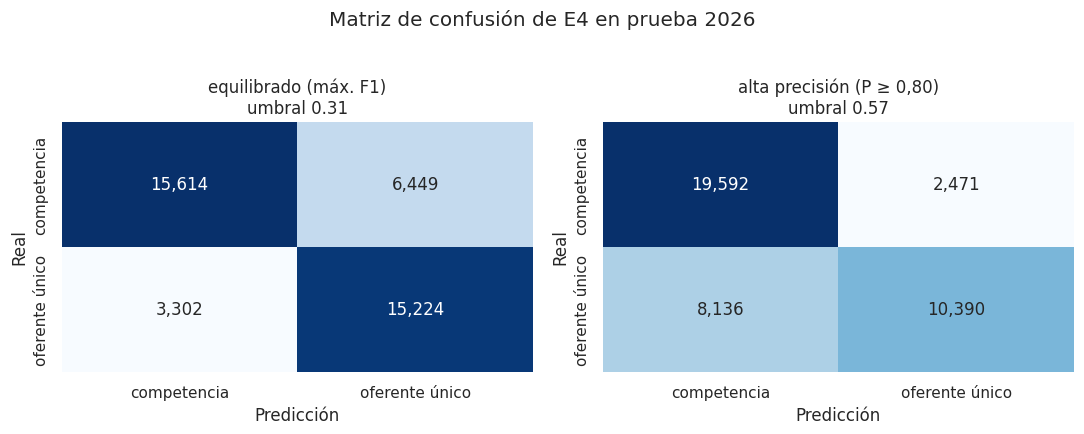

In [11]:
_PRUEBA_ABIERTA = True
y_te = datos_prueba()

# 6.1 Métricas de ranking de todos los experimentos
tabla_te = pd.DataFrame({k: evaluar(y_te, PUNTAJES[k][m_te]) for k in RESULTADOS_VAL}).T
tabla_te.to_csv(DIR_RES / "metricas_prueba_2026.csv")
print("Prueba 2026 (el orden de los modelos se compara con el de validación):")
mostrar(tabla_te)

# 6.2 Métricas por clase del modelo elegido en los dos puntos de operación
p_te = prob_sin_cal[m_te]
NOMBRES_CLASE = ["competencia (0)", "oferente único (1)"]
filas_op = {}
for nombre, u in UMBRALES.items():
    pred = (p_te >= u).astype(int)
    print(f"\n=== {ELEGIDO} — punto de operación {nombre}, umbral {u:.3f} ===")
    print(classification_report(y_te, pred, target_names=NOMBRES_CLASE, digits=3))
    filas_op[nombre] = {"umbral": u, "precisión": precision_score(y_te, pred), "recall": recall_score(y_te, pred),
                        "F1": f1_score(y_te, pred), "exactitud": accuracy_score(y_te, pred),
                        "alertas": int(pred.sum()), "falsos positivos": int(((pred == 1) & (y_te == 0)).sum()),
                        "falsos negativos": int(((pred == 0) & (y_te == 1)).sum())}
tabla_op = pd.DataFrame(filas_op).T
tabla_op.to_csv(DIR_RES / "puntos_operacion_prueba_2026.csv")
mostrar(tabla_op)
print(f"Exactitud de predecir siempre 'competencia': {1 - y_te.mean():.3f}")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (nombre, u) in zip(ejes, UMBRALES.items()):
    mc = confusion_matrix(y_te, (p_te >= u).astype(int))
    sns.heatmap(mc, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["competencia", "oferente único"], yticklabels=["competencia", "oferente único"])
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    ax.set_title(f"{nombre}\numbral {u:.2f}")
plt.suptitle(f"Matriz de confusión de {ELEGIDO} en prueba 2026", y=1.03)
plt.tight_layout()
guardar_figura("02_matrices_confusion")
plt.show()

McNemar E3 vs E4: E3 acierta y E4 falla b = 1,465 | E4 acierta y E3 falla c = 1,657 | chi² = 11.7 | p = 6.30e-04
Diferencia de PR-AUC E4 − E3: +0.0087 (IC 95 % bootstrap: +0.0065 a +0.0108)


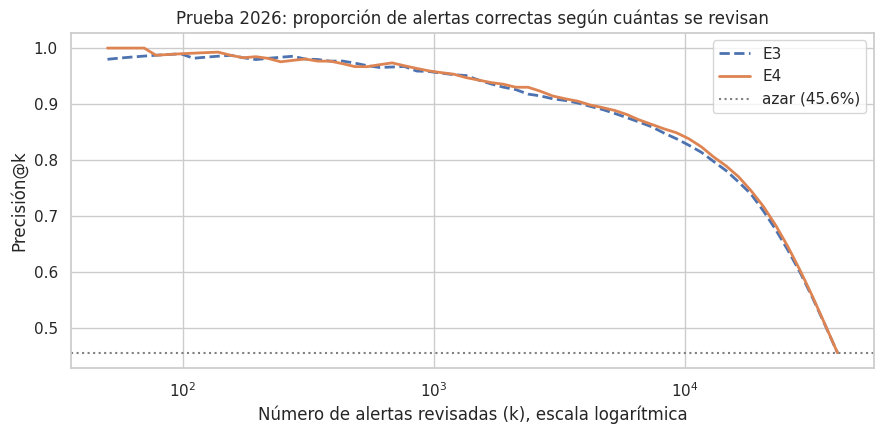

In [12]:
# 6.3 Comparación estadística con E3
def umbral_f1_val(nombre):
    p = prob_corregida(PUNTAJES[nombre][m_va])
    pr, rc, um = precision_recall_curve(y_va, p)
    return float(um[np.argmax((2 * pr * rc / np.clip(pr + rc, 1e-9, None))[:-1])])


def mcnemar(y_real, pred_a, pred_b):
    acierto_a, acierto_b = pred_a == y_real, pred_b == y_real
    b, c = int((acierto_a & ~acierto_b).sum()), int((~acierto_a & acierto_b).sum())
    estad = (abs(b - c) - 1) ** 2 / (b + c)
    return b, c, estad, float(chi2.sf(estad, 1))


pred_E3 = (prob_corregida(PUNTAJES["E3"][m_te]) >= umbral_f1_val("E3")).astype(int)
pred_el = (p_te >= UMBRALES["equilibrado (máx. F1)"]).astype(int)
b, c, estad, valor_p = mcnemar(y_te, pred_E3, pred_el)
print(f"McNemar E3 vs {ELEGIDO}: E3 acierta y {ELEGIDO} falla b = {b:,} | {ELEGIDO} acierta y E3 falla "
      f"c = {c:,} | chi² = {estad:.1f} | p = {valor_p:.2e}")

rng = np.random.default_rng(SEMILLA)
s3, se = PUNTAJES["E3"][m_te], PUNTAJES[ELEGIDO][m_te]
difs = []
for _ in range(1000):
    i = rng.integers(0, len(y_te), len(y_te))
    difs.append(average_precision_score(y_te[i], se[i]) - average_precision_score(y_te[i], s3[i]))
ic = np.percentile(difs, [2.5, 97.5])
print(f"Diferencia de PR-AUC {ELEGIDO} − E3: {np.mean(difs):+.4f} (IC 95 % bootstrap: {ic[0]:+.4f} a {ic[1]:+.4f})")

# 6.4 Precisión según el número de alertas revisadas
ks = np.unique(np.geomspace(50, len(y_te), 60).astype(int))
fig, ax = plt.subplots(figsize=(9, 4.5))
for nombre, estilo in [("E3", "--"), (ELEGIDO, "-")]:
    orden = np.argsort(-PUNTAJES[nombre][m_te], kind="stable")
    acumulada = np.cumsum(y_te[orden]) / np.arange(1, len(y_te) + 1)
    ax.plot(ks, acumulada[ks - 1], estilo, lw=2, label=nombre)
ax.axhline(y_te.mean(), color="gray", ls=":", label=f"azar ({y_te.mean():.1%})")
ax.set_xscale("log")
ax.set_xlabel("Número de alertas revisadas (k), escala logarítmica")
ax.set_ylabel("Precisión@k")
ax.set_title("Prueba 2026: proporción de alertas correctas según cuántas se revisan")
ax.legend()
plt.tight_layout()
guardar_figura("03_precision_en_k")
plt.show()

json.dump({"mcnemar": {"b": b, "c": c, "chi2": estad, "p": valor_p},
           "dif_prauc": {"media": float(np.mean(difs)), "ic95": ic.tolist()}},
          open(DIR_RES / "comparacion_E3_prueba_2026.json", "w"), indent=2)

## 7. Calibración de la probabilidad

**Metodología.** Se compara, en 2026, la curva de confiabilidad (probabilidad predicha frente a frecuencia observada, por deciles) y la **puntuación de Brier**, $\text{BS} = \frac{1}{n}\sum_i (p_i - y_i)^2$, antes y después de la regresión isotónica ajustada en 2025. Un modelo bien calibrado sigue la diagonal: de los procesos con riesgo 70 %, el 70 % recibe una sola oferta. La calibración importa porque la interfaz muestra el riesgo como porcentaje a una usuaria que no es experta en modelos.

**Lectura esperada.** La isotónica reduce el Brier y acerca la probabilidad media a la tasa real, pero no elimina toda la deriva: 2026 tiene una tasa de oferente único (45,6 %) mayor que 2025 (43,1 %). En el despliegue el calibrador se reajusta cada año con el último año completo (sección 10). La pequeña caída de PR-AUC tras calibrar se debe a los empates de la isotónica; no afecta al producto porque el orden se calcula con el puntaje sin calibrar.

sin calibrar: Brier 0.1657 | probabilidad media 0.395 (tasa real 0.456) | PR-AUC 0.8064
isotónica (2025): Brier 0.1616 | probabilidad media 0.432 (tasa real 0.456) | PR-AUC 0.8011


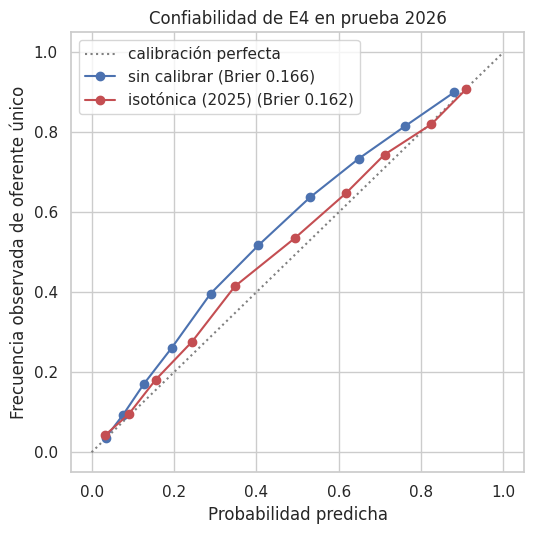

In [13]:
p_cal_te = prob_cal[m_te]
calib = {"sin calibrar": p_te, "isotónica (2025)": p_cal_te}
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], ":", color="gray", label="calibración perfecta")
for (nombre, p), color in zip(calib.items(), [COLOR_COMPETENCIA, COLOR_UNICO]):
    frac, media = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot(media, frac, "o-", color=color, label=f"{nombre} (Brier {brier_score_loss(y_te, p):.3f})")
    print(f"{nombre}: Brier {brier_score_loss(y_te, p):.4f} | probabilidad media {p.mean():.3f} "
          f"(tasa real {y_te.mean():.3f}) | PR-AUC {average_precision_score(y_te, p):.4f}")
ax.set_xlabel("Probabilidad predicha"); ax.set_ylabel("Frecuencia observada de oferente único")
ax.set_title(f"Confiabilidad de {ELEGIDO} en prueba 2026")
ax.legend(loc="upper left")
plt.tight_layout()
guardar_figura("04_calibracion")
plt.show()

## 8. Riesgo relativo a pares y equidad territorial

**Concepto.** Un sistema de alertas es **inequitativo** cuando concentra la vigilancia en un grupo por razones estructurales y no por las características de cada proceso. En el análisis exploratorio, los municipios con menos contratación tienen más oferente único porque hay menos proveedores, no necesariamente por irregularidades (Odilla, 2024). Ordenar solo por el riesgo absoluto llenaría la lista de procesos de municipios pequeños.

**Metodología (E5, del Entregable II).** Cada proceso se compara con sus **pares**: procesos del mismo segmento UNSPSC, modalidad, quintil de cuantía y quintil de tamaño del mercado municipal. El riesgo esperado de los pares se estima con una tasa jerárquica suavizada (de la agrupación más gruesa a la más fina, $\hat p_\text{nivel} = \frac{s + m\,\hat p_\text{nivel anterior}}{n + m}$, $m = 50$, solo con entrenamiento). La prioridad es la diferencia en escala logit:
$$\text{prioridad} = \text{logit}(p_\text{modelo}) - \text{logit}(p_\text{pares})$$
Un proceso sube en la lista cuando su riesgo es **atípico frente a procesos comparables**, no cuando simplemente pertenece a un grupo de riesgo alto.

**Auditoría.** En el 5 % superior de la lista se calcula, por quintil de mercado, la **razón de sobrerrepresentación** = % de alertas / % de procesos (1 = proporcional) y la **brecha** = razón máxima − razón mínima. **Regla de adopción** (igual que en el Entregable II, evaluada en 2025): se ordena por pares si la caída de precisión@1 % es ≤ 10 puntos y la brecha baja.

Validación 2025 — brecha E4 absoluto: 1.65 | E4 + pares: 1.37 | caída de P@1 %: 6.9 puntos -> ordenar por pares: sí

Prueba 2026 — E4 absoluto: brecha 1.54 | P@1 % 0.978
         procesos  tasa_real  % procesos  % alertas  razón sobrerrepresentación  precisión en alertas
quintil                                                                                              
Q1          13536      0.605      33.349     56.382                       1.691                 0.934
Q2           8694      0.533      21.420     25.628                       1.196                 0.917
Q3           7272      0.383      17.916      9.611                       0.536                 0.938
Q4           6541      0.336      16.115      6.654                       0.413                 0.963
Q5           4546      0.159      11.200      1.725                       0.154                 0.971

Prueba 2026 — E4 + pares: brecha 1.24 | P@1 % 0.899
         procesos  tasa_real  % procesos  % alertas  razón sobr

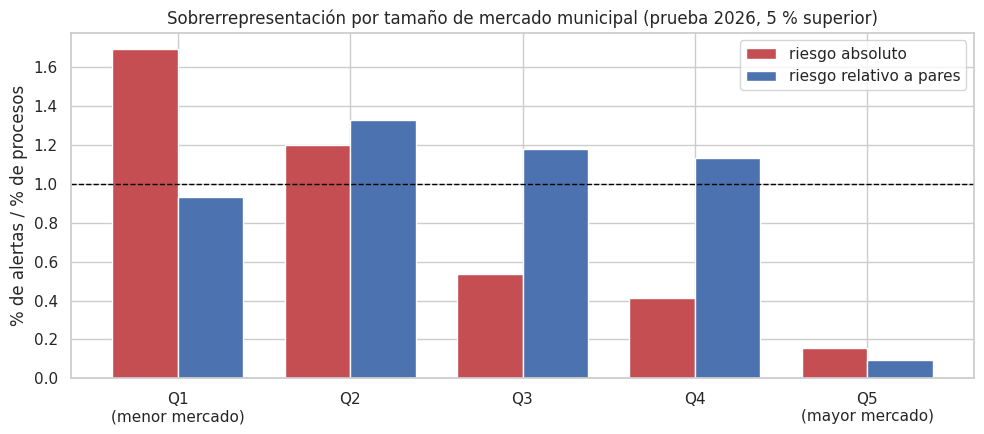

In [14]:
# Tamaño del mercado municipal: publicaciones del municipio en los 365 días previos
df["municipio"] = df["departamento_entidad_txt"] + "|" + df["ciudad_entidad"]
pubs_mun = (df[["municipio", "fecha_de_publicacion_del"]].rename(columns={"fecha_de_publicacion_del": "f"})
            .sort_values("f", kind="stable"))
pubs_mun["acumulado"] = pubs_mun.groupby("municipio").cumcount() + 1


def acumulado_antes(fechas):
    q = pd.DataFrame({"fila": df.index, "municipio": df["municipio"], "f_consulta": fechas.astype(pubs_mun["f"].dtype)})
    q = q.sort_values("f_consulta", kind="stable")
    u = pd.merge_asof(q, pubs_mun, left_on="f_consulta", right_on="f", by="municipio", allow_exact_matches=False)
    return u.set_index("fila").reindex(df.index)["acumulado"].fillna(0)


fecha_pub = df["fecha_de_publicacion_del"]
df["mercado_365"] = (acumulado_antes(fecha_pub) - acumulado_antes(fecha_pub - pd.Timedelta(days=365))).astype("float32")


def quintiles(columna):
    cortes = np.unique(np.quantile(df.loc[m_tr, columna].dropna(), [0.2, 0.4, 0.6, 0.8]))
    bordes = [-np.inf, *cortes, np.inf]
    q = pd.cut(df[columna], bordes, labels=[f"Q{i}" for i in range(1, len(bordes))]).astype(object)
    return q.where(df[columna].notna(), "Sin dato").astype(str), cortes


df["q_mercado"], CORTES_MERCADO = quintiles("mercado_365")
df["q_cuantia"], CORTES_CUANTIA = quintiles("log_precio_base")

NIVELES_PARES = [["segmento_unspsc_txt"],
                 ["segmento_unspsc_txt", "modalidad_de_contratacion_txt"],
                 ["segmento_unspsc_txt", "modalidad_de_contratacion_txt", "q_cuantia"],
                 ["segmento_unspsc_txt", "modalidad_de_contratacion_txt", "q_cuantia", "q_mercado"]]
M_PARES = 50
TABLAS_PARES = []  # estadísticas de entrenamiento por nivel (se exportan en la sección 10)


def tasa_jerarquica(niveles, m=M_PARES):
    previa = pd.Series(P0, index=df.index)
    for columnas in niveles:
        clave = clave_texto(df, columnas)
        estad = pd.DataFrame({"clave": clave[m_tr], "y": y_tr}).groupby("clave")["y"].agg(["sum", "count"])
        TABLAS_PARES.append(estad)
        s, n = clave.map(estad["sum"]).fillna(0), clave.map(estad["count"]).fillna(0)
        previa = (s + m * previa) / (n + m)
    return previa.to_numpy()


riesgo_pares = tasa_jerarquica(NIVELES_PARES)
puntaje_pares = logit(prob_sin_cal) - logit(riesgo_pares)


def auditoria(puntaje_filas, filas, y_real, fraccion=0.05):
    k = int(fraccion * filas.sum())
    alerta = np.zeros(filas.sum(), dtype=bool)
    alerta[np.argsort(-puntaje_filas, kind="stable")[:k]] = True
    t = pd.DataFrame({"quintil": df.loc[filas, "q_mercado"].to_numpy(), "alerta": alerta, "y": y_real})
    g = t.groupby("quintil").agg(procesos=("y", "size"), tasa_real=("y", "mean"), alertas=("alerta", "sum"))
    g["% procesos"] = g["procesos"] / g["procesos"].sum() * 100
    g["% alertas"] = g["alertas"] / g["alertas"].sum() * 100
    g["razón sobrerrepresentación"] = g["% alertas"] / g["% procesos"]
    g["precisión en alertas"] = t[t["alerta"]].groupby("quintil")["y"].mean()
    return g, g["razón sobrerrepresentación"].max() - g["razón sobrerrepresentación"].min()


ABS, PAR = f"{ELEGIDO} absoluto", f"{ELEGIDO} + pares"
eq_val = {ABS: auditoria(puntaje[m_va], m_va, y_va), PAR: auditoria(puntaje_pares[m_va], m_va, y_va)}
p1 = {n: precision_en_k(y_va, s[m_va], int(0.01 * m_va.sum())) for n, s in [(ABS, puntaje), (PAR, puntaje_pares)]}
caida = p1[ABS] - p1[PAR]
ADOPTAR_PARES = (caida <= 0.10) and (eq_val[PAR][1] < eq_val[ABS][1])
print(f"Validación 2025 — brecha {ABS}: {eq_val[ABS][1]:.2f} | {PAR}: {eq_val[PAR][1]:.2f} | "
      f"caída de P@1 %: {caida * 100:.1f} puntos -> ordenar por pares: {'sí' if ADOPTAR_PARES else 'no'}")

eq_te = {ABS: auditoria(puntaje[m_te], m_te, y_te), PAR: auditoria(puntaje_pares[m_te], m_te, y_te)}
for nombre, (tabla, brecha) in eq_te.items():
    print(f"\nPrueba 2026 — {nombre}: brecha {brecha:.2f} | P@1 % {precision_en_k(y_te, (puntaje if nombre == ABS else puntaje_pares)[m_te], int(0.01 * m_te.sum())):.3f}")
    mostrar(tabla[["procesos", "tasa_real", "% procesos", "% alertas", "razón sobrerrepresentación", "precisión en alertas"]])
pd.concat({n: t for n, (t, _) in eq_te.items()}).to_csv(DIR_RES / "equidad_prueba_2026.csv")

fig, ax = plt.subplots(figsize=(10, 4.5))
qs = eq_te[ABS][0].index
x, ancho = np.arange(len(qs)), 0.38
ax.bar(x - ancho / 2, eq_te[ABS][0]["razón sobrerrepresentación"], ancho, label="riesgo absoluto", color=COLOR_UNICO)
ax.bar(x + ancho / 2, eq_te[PAR][0]["razón sobrerrepresentación"], ancho, label="riesgo relativo a pares", color=COLOR_COMPETENCIA)
ax.axhline(1, color="black", ls="--", lw=1)
ax.set_xticks(x, [f"{q}\n{'(menor mercado)' if q == 'Q1' else '(mayor mercado)' if q == 'Q5' else ''}" for q in qs])
ax.set_ylabel("% de alertas / % de procesos")
ax.set_title("Sobrerrepresentación por tamaño de mercado municipal (prueba 2026, 5 % superior)")
ax.legend()
plt.tight_layout()
guardar_figura("05_equidad_territorial")
plt.show()

## 9. Explicabilidad (SHAP)

**Concepto.** SHAP (Lundberg y Lee, 2017) reparte la predicción de un proceso entre sus variables con los **valores de Shapley** de la teoría de juegos cooperativos: $\text{logit}(p) = \phi_0 + \sum_j \phi_j$, donde $\phi_0$ es el valor base y $\phi_j$ la contribución promedio de la variable $j$ sobre todos los órdenes posibles de incorporación. Con `TreeExplainer` el cálculo es exacto para modelos de árboles.

**Metodología.** Una alerta sin justificación no sirve para iniciar una revisión; por eso cada alerta lleva sus factores. Las 100 componentes TF-IDF/SVD no tienen significado individual, así que sus contribuciones se **suman** en un solo factor, «Texto del objeto contractual» (los valores SHAP son aditivos). Para que ese factor sea legible, cada alerta muestra además los **términos más distintivos** de su objeto (mayor peso TF-IDF). Las contribuciones se leen como factores **asociados** a una menor competencia esperada, no como evidencia de una conducta.

SHAP de 3000 procesos en 10 s
                                                    % de la importancia media |SHAP|
Tasa previa de oferente único (entidad)                                         17.0
Texto del objeto contractual                                                    12.5
Segmento UNSPSC                                                                 11.2
Tasa previa de oferente único (entidad y segmento)                              10.7
Mes de publicación                                                               6.6
Modalidad                                                                        6.5
Precio base                                                                      6.4
Departamento                                                                     4.8
Tipo de contrato                                                                 4.5
Días para ofertar                                                                3.3


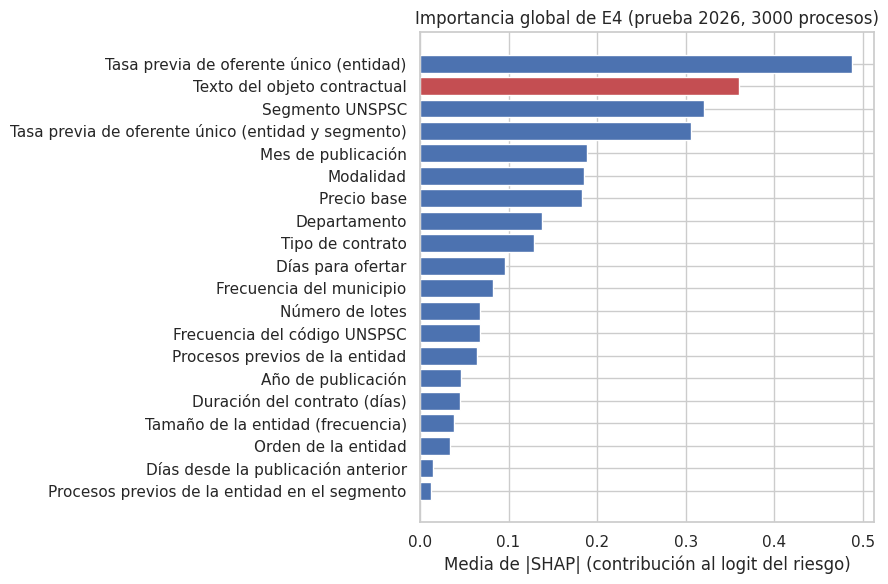


Ejemplo: Prestación del servicio de vigilancia con medio humano, sin arma, sin canino, con equipo de comunicación y monitoreo de  -> sede barrio, comunicacion monitoreo, sur sede, cefit ubicadas, barrio mesa


In [15]:
NOMBRES_LEGIBLES = {
    "modalidad_de_contratacion": "Modalidad", "tipo_de_contrato": "Tipo de contrato",
    "ordenentidad": "Orden de la entidad", "segmento_unspsc": "Segmento UNSPSC",
    "departamento_entidad": "Departamento", "frec_entidad": "Tamaño de la entidad (frecuencia)",
    "frec_codigo_principal_de_categoria": "Frecuencia del código UNSPSC",
    "frec_ciudad_entidad": "Frecuencia del municipio", "log_precio_base": "Precio base",
    "duracion_dias": "Duración del contrato (días)", "dias_para_ofertar": "Días para ofertar",
    "numero_de_lotes": "Número de lotes", "mes": "Mes de publicación", "anio": "Año de publicación",
    "ent_n_prev": "Procesos previos de la entidad", "ent_tasa_prev": "Tasa previa de oferente único (entidad)",
    "entseg_n_prev": "Procesos previos de la entidad en el segmento",
    "entseg_tasa_prev": "Tasa previa de oferente único (entidad y segmento)",
    "ent_dias_desde_ultimo": "Días desde la publicación anterior",
    "TEXTO": "Texto del objeto contractual",
}
explicador = shap.TreeExplainer(modelo_final)


def shap_agrupado(X):
    # Valores SHAP con las componentes de texto sumadas en un único factor 'TEXTO'
    v = explicador.shap_values(X)
    v = v[1] if isinstance(v, list) else v
    v = pd.DataFrame(v, columns=VARS_FINAL, index=X.index)
    texto = [c for c in VARS_FINAL if c.startswith(("tfidf_", "beto_"))]
    if texto:
        v["TEXTO"] = v[texto].sum(axis=1)
        v = v.drop(columns=texto)
    return v


idx_te = np.where(m_te)[0]
muestra = np.random.default_rng(SEMILLA).choice(idx_te, size=3000, replace=False)
inicio = time.time()
sv = shap_agrupado(df.loc[muestra, VARS_FINAL])
print(f"SHAP de 3000 procesos en {time.time() - inicio:.0f} s")
imp = sv.abs().mean().sort_values()
imp.index = [NOMBRES_LEGIBLES.get(c, c) for c in imp.index]
mostrar((imp / imp.sum() * 100).sort_values(ascending=False).head(10).to_frame("% de la importancia media |SHAP|"), 1)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp.index, imp.values, color=[COLOR_UNICO if i == "Texto del objeto contractual" else COLOR_COMPETENCIA for i in imp.index])
ax.set_xlabel("Media de |SHAP| (contribución al logit del riesgo)")
ax.set_title(f"Importancia global de {ELEGIDO} (prueba 2026, 3000 procesos)")
plt.tight_layout()
guardar_figura("06_shap_global")
plt.show()

# Términos más distintivos de un objeto contractual (mayor peso TF-IDF)
VOCAB = np.array(tfidf.get_feature_names_out())


def terminos_clave(i, n=5):
    fila = M_tfidf[i]
    orden = np.argsort(-fila.data)[:n]
    return ", ".join(VOCAB[fila.indices[orden]])


print("\nEjemplo:", df.loc[idx_te[0], "descripcion"][:120], "->", terminos_clave(idx_te[0]))

### 9.1 Lista priorizada y explicada (salida del producto)

**Metodología.** Esta es la salida que recibe la usuaria y la misma lógica que ejecuta el *pipeline* semanal del despliegue. Para cada proceso:

| Campo | Origen |
|---|---|
| `prioridad` | Posición según el riesgo relativo a pares (sección 8) |
| `riesgo_%` | Probabilidad **calibrada** de oferente único (sección 7) |
| `riesgo_pares_%` | Riesgo esperado de procesos comparables |
| `alerta` | Supera el umbral de alta precisión fijado en 2025 |
| `factores` | Las tres variables con mayor contribución SHAP positiva, en lenguaje natural |
| `terminos_clave` | Términos más distintivos del objeto (TF-IDF) |

Se calcula para **todos los procesos de 2026**; la tabla resultante (capa *Gold*) alimenta la demostración de la aplicación web con datos ya evaluados, y la columna `resultado_observado` permite mostrar en la presentación cuántas alertas fueron correctas.

In [16]:
def describir(variable, valor):
    nombre = NOMBRES_LEGIBLES.get(variable, variable)
    if variable == "TEXTO":
        return nombre
    if variable == "log_precio_base":
        return f"{nombre} = ${10 ** float(valor) / 1e6:,.0f} M"
    if isinstance(valor, (float, np.floating)):
        if np.isnan(valor):
            return f"{nombre} = sin dato"
        if variable.endswith("_tasa_prev"):
            return f"{nombre} = {valor:.0%}"
        return f"{nombre} = {int(valor):,}" if float(valor).is_integer() else f"{nombre} = {valor:,.2f}"
    return f"{nombre} = {valor}"


def explicar(indices, lote=5000):
    # Factores SHAP (3 mayores contribuciones positivas) y términos clave de cada proceso
    factores = []
    for i in range(0, len(indices), lote):
        bloque = indices[i:i + lote]
        v = shap_agrupado(df.loc[bloque, VARS_FINAL])
        for fila, contrib in zip(bloque, v.to_numpy()):
            orden = [j for j in np.argsort(-contrib)[:3] if contrib[j] > 0]
            factores.append(" | ".join(describir(v.columns[j], df.loc[fila, v.columns[j]] if v.columns[j] != "TEXTO" else None)
                                       for j in orden))
    return factores, [terminos_clave(i) for i in indices]


def riesgo_mostrado(p_calibrada):
    # La isotónica satura en 0 y 1 en los tramos extremos; un modelo no da certeza: se muestra entre 1 % y 99 %
    return (np.clip(p_calibrada, 0.01, 0.99) * 100).round(1)


inicio = time.time()
prioridad = puntaje_pares if ADOPTAR_PARES else puntaje
orden_te = idx_te[np.argsort(-prioridad[m_te], kind="stable")]
factores, terminos = explicar(orden_te)
gold_2026 = pd.DataFrame({
    "prioridad": np.arange(1, len(orden_te) + 1),
    "id_del_proceso": df.loc[orden_te, "id_del_proceso"].to_numpy(),
    "referencia": df.loc[orden_te, "referencia_del_proceso"].to_numpy(),
    "fecha_publicacion": df.loc[orden_te, "fecha_de_publicacion_del"].dt.date.astype(str).to_numpy(),
    "entidad": df.loc[orden_te, "entidad"].to_numpy(),
    "nit_entidad": df.loc[orden_te, "nit_entidad"].to_numpy(),
    "departamento": df.loc[orden_te, "departamento_entidad_txt"].to_numpy(),
    "municipio": df.loc[orden_te, "ciudad_entidad"].to_numpy(),
    "modalidad": df.loc[orden_te, "modalidad_de_contratacion_txt"].to_numpy(),
    "tipo_contrato": df.loc[orden_te, "tipo_de_contrato_txt"].to_numpy(),
    "objeto": df.loc[orden_te, "descripcion"].to_numpy(),
    "precio_base": df.loc[orden_te, "precio_base"].to_numpy(),
    "dias_para_ofertar": df.loc[orden_te, "dias_para_ofertar"].to_numpy(),
    "riesgo_pct": riesgo_mostrado(prob_cal[orden_te]),
    "riesgo_pares_pct": (riesgo_pares[orden_te] * 100).round(1),
    "puntaje_prioridad": prioridad[orden_te].round(4),
    "alerta": prob_sin_cal[orden_te] >= UMBRALES["alta precisión (P ≥ 0,80)"],
    "factores": factores,
    "terminos_clave": terminos,
    "resultado_observado": np.where(y[orden_te] == 1, "1 oferta", "2 o más ofertas"),
})
gold_2026.to_parquet(DIR_RES / "gold_alertas_2026.parquet", index=False)
print(f"Lista de {len(gold_2026):,} procesos de 2026 explicada en {time.time() - inicio:.0f} s | "
      f"alertas de alta precisión: {gold_2026['alerta'].sum():,}")
print("\nLISTA PRIORIZADA PARA REVISIÓN HUMANA — 10 primeros procesos de 2026")
print("Priorizar, no señalar: el riesgo de oferente único no es evidencia de corrupción ni de ninguna falta.\n")
for _, r in gold_2026.head(10).iterrows():
    print(f"#{r.prioridad} {r.entidad[:50]} ({r.municipio}) | {r.modalidad} | riesgo {r.riesgo_pct}% vs pares "
          f"{r.riesgo_pares_pct}% | {r.resultado_observado}\n    objeto: {r.objeto[:100]}\n    factores: {r.factores}\n"
          f"    términos: {r.terminos_clave}")
print(f"\nPrecisión en las 100 primeras: {(gold_2026.head(100)['resultado_observado'] == '1 oferta').mean():.0%}")

Lista de 40,589 procesos de 2026 explicada en 140 s | alertas de alta precisión: 12,861

LISTA PRIORIZADA PARA REVISIÓN HUMANA — 10 primeros procesos de 2026
Priorizar, no señalar: el riesgo de oferente único no es evidencia de corrupción ni de ninguna falta.

#1 MUNICIPIO DE SANTA ROSA DEL SUR (Santa Rosa Del Sur) | Selección abreviada subasta inversa | riesgo 91.0% vs pares 14.8% | 1 oferta
    objeto: PRESTACION DE SERVICIOS INTEGRALES PARA LA ATENCIÓN DE LOS PROGRAMAS CENTRO DIA Y CENTRO DE PROTECCI
    factores: Tasa previa de oferente único (entidad) = 74% | Modalidad = Selección abreviada subasta inversa | Texto del objeto contractual
    términos: dia centro, sur bolivar, proteccion al, rosa del, integrales para
#2 MUNICIPIO DE LABRANZAGRANDE (No Definido) | Selección Abreviada de Menor Cuantía | riesgo 99.0% vs pares 53.3% | 1 oferta
    objeto: FORTALECIMIENTO DEL BANCO DE MAQUINARIA MEDIANTE EL SUMINISTRO DE COMBUSTIBLE, PARA LA MAQUINARIA Y 
    factores: Texto del objeto c

## 10. Exportación de artefactos para el despliegue

**Metodología.** El despliegue separa el **entrenamiento** (este notebook, con GPU, una vez al año) de la **inferencia** (un *pipeline* semanal en CPU que puntúa los procesos recién publicados en SECOP II y una aplicación web que muestra la lista). Para que el *pipeline* reproduzca exactamente las variables de este notebook sin volver a leer 400 000 procesos, se exporta el **estado** de cada transformación ajustada:

| Artefacto | Contenido | Lo usa |
|---|---|---|
| `modelo_lgbm.txt` | Árboles de LightGBM en formato de texto (independiente de Python) | Puntaje |
| `texto_tfidf_svd.joblib` | Vectorizador TF-IDF y SVD ajustados en 2017–2024 | Variables de texto |
| `calibrador_isotonico.joblib` | Regresión isotónica ajustada en 2025 | Probabilidad mostrada |
| `frecuencias.parquet` | Frecuencia relativa de entidad, código UNSPSC y municipio | Variables de alta cardinalidad |
| `historial_entidad.parquet`, `historial_entidad_segmento.parquet` | Procesos adjudicados y con oferente único acumulados por clave, y última publicación de la entidad | Historial sin fuga |
| `publicaciones_365d.parquet` | Publicaciones por municipio del último año | Tamaño del mercado (pares) |
| `pares.parquet` | Conteos de entrenamiento por nivel de la jerarquía de pares | Riesgo de los pares |
| `metadatos.json` | Variables, categorías, cortes de quintiles, umbrales, constantes, versiones y métricas | Todo el *pipeline* |

**Técnica.** El *pipeline* debe usar las mismas versiones de scikit-learn y LightGBM registradas en `metadatos.json`: los objetos `joblib` no son portables entre versiones. El historial exportado refleja los procesos adjudicados hasta la fecha de corte del conjunto; el *pipeline* lo actualiza cada semana con los procesos adjudicados nuevos.

In [17]:
FECHA_CORTE = df["fecha_de_publicacion_del"].max()

# Modelo, texto y calibrador
modelo_final.booster_.save_model(str(DIR_ART / "modelo_lgbm.txt"), num_iteration=modelo_final.best_iteration_)
joblib.dump({"tfidf": tfidf, "svd": svd}, DIR_ART / "texto_tfidf_svd.joblib", compress=3)
joblib.dump(calibrador, DIR_ART / "calibrador_isotonico.joblib")

# Frecuencias de alta cardinalidad
pd.concat([s.rename("frecuencia").rename_axis("valor").reset_index().assign(columna=c)
           for c, s in FRECUENCIAS.items()]).to_parquet(DIR_ART / "frecuencias.parquet", index=False)

# Estado acumulado del historial (n procesos adjudicados y s con oferente único por clave)
def estado(ev):
    return ev.groupby("clave").agg(n=("n_prev", "max"), s=("s_prev", "last"),
                                   ultima_adjudicacion=("fecha_adjudicacion", "max")).reset_index()


hist_ent = estado(ev_ent).merge(
    df.groupby("entidad")["fecha_de_publicacion_del"].max().rename("ultima_publicacion").reset_index()
      .rename(columns={"entidad": "clave"}), on="clave", how="outer")
hist_ent.to_parquet(DIR_ART / "historial_entidad.parquet", index=False)
estado(ev_entseg).to_parquet(DIR_ART / "historial_entidad_segmento.parquet", index=False)

# Publicaciones del último año por municipio (tamaño del mercado)
(pubs_mun.loc[pubs_mun["f"] > FECHA_CORTE - pd.Timedelta(days=365), ["municipio", "f"]]
 .rename(columns={"f": "fecha_publicacion"}).to_parquet(DIR_ART / "publicaciones_365d.parquet", index=False))

# Jerarquía de pares
pd.concat([t.reset_index().assign(nivel=i) for i, t in enumerate(TABLAS_PARES[-len(NIVELES_PARES):])]
          ).to_parquet(DIR_ART / "pares.parquet", index=False)

metadatos = {
    "modelo": ELEGIDO, "fecha_entrenamiento": pd.Timestamp.now().isoformat(timespec="seconds"),
    "fecha_corte_datos": str(FECHA_CORTE.date()),
    "particion": {"entrenamiento": "2017-2024", "validacion": "2025", "prueba": "2026"},
    "variables": VARS_FINAL, "cat_baja": CAT_BAJA, "cat_alta": CAT_ALTA, "numericas": NUMERICAS,
    "historial": HISTORIAL, "variables_texto": [v for v in VARS_FINAL if v.startswith(("tfidf_", "beto_"))],
    "categorias": CATEGORIAS, "peso_pos": PESO_POS, "p0": P0, "m_suav": M_SUAV,
    "niveles_pares": NIVELES_PARES, "m_pares": M_PARES, "ordenar_por_pares": bool(ADOPTAR_PARES),
    "cortes_mercado": CORTES_MERCADO.tolist(), "cortes_cuantia": CORTES_CUANTIA.tolist(),
    "umbrales": UMBRALES, "umbral_alerta": UMBRALES["alta precisión (P ≥ 0,80)"],
    "nombres_legibles": NOMBRES_LEGIBLES, "versiones": VERSIONES,
    "metricas_prueba_2026": {k: round(float(v), 4) for k, v in tabla_te.loc[ELEGIDO].items()},
    "puntos_operacion_prueba_2026": {k: {c: round(float(x), 4) for c, x in v.items()} for k, v in tabla_op.T.to_dict().items()},
}
with open(DIR_ART / "metadatos.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)

for archivo in sorted(DIR_ART.iterdir()):
    print(f"{archivo.name:42s} {archivo.stat().st_size / 1e6:8.2f} MB")

calibrador_isotonico.joblib                    0.00 MB
frecuencias.parquet                            0.15 MB
historial_entidad.parquet                      0.10 MB
historial_entidad_segmento.parquet             0.61 MB
metadatos.json                                 0.01 MB
modelo_lgbm.txt                                4.10 MB
pares.parquet                                  0.06 MB
publicaciones_365d.parquet                     0.09 MB
texto_tfidf_svd.joblib                        38.85 MB


## 11. Conclusiones

**Respuesta a la pregunta de investigación.** Sí es posible estimar, el día de la publicación y sin fuga de información, la probabilidad de que un proceso reciba un solo oferente. En 2026, un año que no intervino en ninguna decisión, el modelo final (E4: LightGBM con historial de la entidad y texto del objeto) alcanza PR-AUC 0,806 (azar 0,456) y ROC-AUC 0,843, y el 97,8 % de sus alertas en el 1 % superior de la lista correspondió a oferente único.

**Sobre el texto del objeto contractual.**
- El texto aporta una mejora **pequeña pero estadísticamente significativa** sobre E3: +0,009 de PR-AUC (IC 95 % bootstrap de +0,007 a +0,011) y McNemar con $p < 0{,}001$. En SHAP es el segundo factor más importante después del historial de la entidad.
- **TF-IDF iguala a BETO congelado.** En un corpus de vocabulario administrativo y formulaico, una representación de frecuencias captura lo mismo que los embeddings de un Transformer preentrenado, con una fracción del costo. La media de las subpalabras supera al [CLS] cuando BERT no se ajusta.
- Parte de la señal del texto es **territorial**: entre los términos distintivos aparecen nombres de municipios. El texto no solo describe la necesidad, también identifica el lugar.

**Sobre los errores.** El falso positivo es el error costoso (capacidad de revisión limitada y riesgo de señalar sin razón). En el punto de alta precisión, el 80,8 % de las alertas es correcto a cambio de detectar el 56 % de los oferentes únicos; en el punto equilibrado, 70 % y 82 %. La recomendación es operar por **capacidad**: revisar los *k* primeros de la lista, donde la precisión supera el 90 %.

**Sobre la equidad.** Ordenar por el riesgo relativo a pares reduce la brecha de sobrerrepresentación de 1,54 a 1,24: el quintil de menor mercado pasa de recibir el 56 % de las alertas al 31 % (es el 33 % de los procesos), a costa de bajar la precisión@1 % de 0,978 a 0,899.

**Del modelo al producto.** Los artefactos de la sección 10 alimentan el despliegue:

| Componente | Implementación |
|---|---|
| *Pipeline* semanal | Ingesta desde la API de SECOP II → *bronze* (Parquet crudo) → *silver* con **Apache Spark** (última versión de cada proceso, variables del análisis exploratorio) → *gold* (historial sin fuga actualizado con los adjudicados nuevos, puntaje, calibración, pares y SHAP). Orquestado con GitHub Actions cada lunes (también con un DAG de Airflow) |
| Lakehouse | Repositorio de datos en Hugging Face: [secop-oferente-unico-lakehouse](https://huggingface.co/datasets/JuanEstevan-DataEng/secop-oferente-unico-lakehouse) |
| Aplicación web | FastAPI + página web en Docker (Render): lista priorizada de procesos abiertos, ficha explicada con enlace a SECOP II, evaluación 2026 y simulador. **https://alerta-oferente-unico.onrender.com** |
| Código fuente | [github.com/JuanEstevan-DataEng/alerta-oferente-unico](https://github.com/JuanEstevan-DataEng/alerta-oferente-unico) |

El paquete de inferencia del despliegue reproduce este notebook en el 100 % de los 40 589 procesos de 2026 (riesgo, pares, alertas y factores).

**Validación prospectiva del sistema desplegado.** Se simuló la ejecución semanal en las seis semanas posteriores al corte de los datos (25 de septiembre a 30 de octubre de 2026), usando solo la información disponible cada día, y se comparó con el resultado que hoy ya se conoce (7 210 procesos): PR-AUC 0,783, precisión de las 50 primeras alertas de cada semana entre 0,86 y 0,96, precisión de las alertas 0,69 y recall 0,78. El orden de la lista se sostiene fuera del periodo de entrenamiento.

**Limitaciones.**
- El oferente único es un **indicador sustituto**: el sistema prioriza riesgo de baja competencia, no detecta corrupción.
- Solo se observan procesos adjudicados; los cancelados o desiertos quedan fuera.
- La deriva temporal persiste (34,7 % en entrenamiento, 45,6 % en 2026 y 44,8–47 % en las semanas recientes). En producción, el historial actualizado ya incorpora la deriva y el calibrador de 2025 **sobreestima** (probabilidad media 0,57 frente a una tasa real de 0,45): hay que reajustar el calibrador con las semanas cuyo resultado ya se conoce y reentrenar el modelo cada año.
- SECOP II edita los registros después de publicarlos (el 21 % de una muestra de 2026 cambió su código UNSPSC principal); por eso *bronze* conserva cada versión tal como llegó.
- La validación con usuarios fue limitada: el acceso a funcionarios de contratación es restringido.